 Route choice and Braess’s paradox in the Barcelona rail–metro network

**Manresa → Ciutadella | Vila Olímpica**

We compare the current network and the proposed L4 extension at La Sagrera. For each draw of passenger demand and metro capacity, we calculate the cost of both networks with and without additional waiting due to congestion. An increase in the equilibrium cost after adding the connection is the test for Braess’s paradox.

Run the cells in order. The notebook includes the required data extracts. If a package is missing, run `%pip install numpy pandas scipy matplotlib` in a notebook cell. Reading the original FMB workbook also requires `openpyxl`.

All costs are in **weighted minutes per passenger**. The separate journey-time outputs use clock minutes.

# 1. Settings and assumptions

The demand reference of 20,000 is an illustrative daily count. The assumed shares for the time window, direction and destination give a median of $Q_0=25$ Manresa–UPF passengers in the two-hour window. The FMB station counts are used separately for metro background demand.

In [1]:
from pathlib import Path
import hashlib
import json
import re

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize

DATA_MODE = "embedded"  # Use "source_files" to re-extract from the supplied files.
DATA_FOLDER = Path("data")
GTFS_DATE = "2026-11-16"
START_TIME, END_TIME = "08:00:00", "10:00:00"
FMB_MONTH = 10  # October 2025, the month used in the earlier notebook.

N_SCENARIOS = 500
SEED = 20261113
CHANGE_TOL = 0.01       # Weighted minutes per passenger.
WARDROP_TOL = 0.0001   # Maximum gain from switching routes.
WAIT_WEIGHT, WALK_WEIGHT = 1.75, 1.50

DAILY_DEMAND_REFERENCE = 20_000
WINDOW_SHARE = 0.10
DIRECTION_SHARE = 0.50
DESTINATION_SHARE = 0.025
BACKGROUND_SCALE = 0.05
Q_BASE = DAILY_DEMAND_REFERENCE * WINDOW_SHARE * DIRECTION_SHARE * DESTINATION_SHARE

DEMAND_LOG_SD = 0.15
BACKGROUND_LOG_SD = 0.10
SPARE_CAPACITY_LOG_SD = 0.08

# Order: L1, L5, L4 via Urquinaona, L4 departing La Sagrera.
METRO_CAPACITY = np.array([100.0, 100.0, 100.0, 100.0])  # Assumed effective places per train.
METRO_ONBOARD_SHARE = np.array([0.80, 0.75, 0.80, 0.00])
TERMINAL_BACKGROUND_IN_WINDOW = 0.0  # Quiet-terminal scenario. Edit to add competing boarders.

# Group's travel and transfer assumptions, in unweighted minutes.
R4_TO_ARC = 78.0
R4_TO_SAGRERA = 71.0
WALK_R4_TO_L1_AT_ARC = 1.0
WALK_R4_TO_L1_AT_SAGRERA = 1.0
WALK_R4_TO_L5_AT_SAGRERA = 1.0
WALK_L1_TO_L4_AT_URQUINAONA = 3.0
WALK_L5_TO_L4_AT_VERDAGUER = 2.0
WALK_R4_TO_L4_AT_SAGRERA = 1.0

EXTENSION_RIDE_MIN = (36.0 / 21) * 3  # Group estimate: three new interstation intervals.
TERMINAL_HEADWAY_MIN = 4.0
EXISTING_L4_RIDE_OVERRIDE = None  # Set to 12.0 to match the rounded value in the group notes.

print(f"Median simulated Manresa–UPF demand: {Q_BASE:.1f} passengers per window.")

Median simulated Manresa–UPF demand: 25.0 passengers per window.


# 2. Input data

The TMB GTFS extract contains scheduled in-vehicle times, train intervals and mean scheduled waits for the selected directions. Scheduled waits assume uniform arrivals at each boarding point. FMB weekday station totals inform the scale of background demand. The FMB and GTFS extracts refer to different years.

In [2]:
SNAPSHOT = {
  "schedule_window": [
    "2026-11-16",
    "08:00:00",
    "10:00:00"
  ],
  "gtfs": [
    {
      "segment": "Arc to Urquinaona",
      "line": "L1",
      "headsign": "Hospital de Bellvitge",
      "direction_id": "1",
      "ride_min": 1.0499999999999996,
      "headway_min": 3.029166666666667,
      "scheduled_wait_min": 1.5149074074074074,
      "departures": 39
    },
    {
      "segment": "La Sagrera to Urquinaona",
      "line": "L1",
      "headsign": "Hospital de Bellvitge",
      "direction_id": "1",
      "ride_min": 9.193859649122805,
      "headway_min": 3.0944444444444446,
      "scheduled_wait_min": 1.5698912037037038,
      "departures": 38
    },
    {
      "segment": "La Sagrera to Verdaguer",
      "line": "L5",
      "headsign": "Cornellà Centre",
      "direction_id": "1",
      "ride_min": 6.766666666666667,
      "headway_min": 2.5054421768707478,
      "scheduled_wait_min": 1.2712361111111112,
      "departures": 48
    },
    {
      "segment": "Urquinaona to Vila Olímpica",
      "line": "L4",
      "headsign": "La Pau",
      "direction_id": "1",
      "ride_min": 4.366666666666665,
      "headway_min": 4.23735632183908,
      "scheduled_wait_min": 2.1491458333333333,
      "departures": 28
    },
    {
      "segment": "Verdaguer to Vila Olímpica",
      "line": "L4",
      "headsign": "La Pau",
      "direction_id": "1",
      "ride_min": 9.566666666666666,
      "headway_min": 4.275862068965517,
      "scheduled_wait_min": 2.1698287037037036,
      "departures": 28
    },
    {
      "segment": "La Pau to Vila Olímpica",
      "line": "L4",
      "headsign": "Trinitat Nova",
      "direction_id": "0",
      "ride_min": 12.33333333333333,
      "headway_min": 4.295402298850574,
      "scheduled_wait_min": 2.1746458333333334,
      "departures": 28
    }
  ],
  "fmb": [
    {
      "line": "L1",
      "station": "ARC DE TRIOMF",
      "month": 1,
      "year": 2025,
      "weekday_passengers": 16803.619047619,
      "cell": "D24"
    },
    {
      "line": "L1",
      "station": "ARC DE TRIOMF",
      "month": 2,
      "year": 2025,
      "weekday_passengers": 18281.3,
      "cell": "E24"
    },
    {
      "line": "L1",
      "station": "ARC DE TRIOMF",
      "month": 3,
      "year": 2025,
      "weekday_passengers": 18457.7619047619,
      "cell": "F24"
    },
    {
      "line": "L1",
      "station": "ARC DE TRIOMF",
      "month": 4,
      "year": 2025,
      "weekday_passengers": 18546.25,
      "cell": "G24"
    },
    {
      "line": "L1",
      "station": "ARC DE TRIOMF",
      "month": 5,
      "year": 2025,
      "weekday_passengers": 18729.2380952381,
      "cell": "H24"
    },
    {
      "line": "L1",
      "station": "ARC DE TRIOMF",
      "month": 6,
      "year": 2025,
      "weekday_passengers": 18421.2105263158,
      "cell": "I24"
    },
    {
      "line": "L1",
      "station": "ARC DE TRIOMF",
      "month": 7,
      "year": 2025,
      "weekday_passengers": 18102.0434782609,
      "cell": "J24"
    },
    {
      "line": "L1",
      "station": "ARC DE TRIOMF",
      "month": 8,
      "year": 2025,
      "weekday_passengers": 15240.2,
      "cell": "K24"
    },
    {
      "line": "L1",
      "station": "ARC DE TRIOMF",
      "month": 9,
      "year": 2025,
      "weekday_passengers": 17833.7,
      "cell": "L24"
    },
    {
      "line": "L1",
      "station": "ARC DE TRIOMF",
      "month": 10,
      "year": 2025,
      "weekday_passengers": 19167.88360397819,
      "cell": "M24"
    },
    {
      "line": "L1",
      "station": "ARC DE TRIOMF",
      "month": 11,
      "year": 2025,
      "weekday_passengers": 18041.1,
      "cell": "N24"
    },
    {
      "line": "L1",
      "station": "ARC DE TRIOMF",
      "month": 12,
      "year": 2025,
      "weekday_passengers": 16710.6,
      "cell": "O24"
    },
    {
      "line": "L4",
      "station": "URQUINAONA",
      "month": 1,
      "year": 2025,
      "weekday_passengers": 12896.0579755057,
      "cell": "D116"
    },
    {
      "line": "L4",
      "station": "URQUINAONA",
      "month": 2,
      "year": 2025,
      "weekday_passengers": 10927.6653414351,
      "cell": "E116"
    },
    {
      "line": "L4",
      "station": "URQUINAONA",
      "month": 3,
      "year": 2025,
      "weekday_passengers": 11620.9909795594,
      "cell": "F116"
    },
    {
      "line": "L4",
      "station": "URQUINAONA",
      "month": 4,
      "year": 2025,
      "weekday_passengers": 12608.2279269165,
      "cell": "G116"
    },
    {
      "line": "L4",
      "station": "URQUINAONA",
      "month": 5,
      "year": 2025,
      "weekday_passengers": 12974.1246489686,
      "cell": "H116"
    },
    {
      "line": "L4",
      "station": "URQUINAONA",
      "month": 6,
      "year": 2025,
      "weekday_passengers": 12387.3442455448,
      "cell": "I116"
    },
    {
      "line": "L4",
      "station": "URQUINAONA",
      "month": 7,
      "year": 2025,
      "weekday_passengers": 9147.67155446156,
      "cell": "J116"
    },
    {
      "line": "L4",
      "station": "URQUINAONA",
      "month": 8,
      "year": 2025,
      "weekday_passengers": 7438.12923958909,
      "cell": "K116"
    },
    {
      "line": "L4",
      "station": "URQUINAONA",
      "month": 9,
      "year": 2025,
      "weekday_passengers": 11477.844495127,
      "cell": "L116"
    },
    {
      "line": "L4",
      "station": "URQUINAONA",
      "month": 10,
      "year": 2025,
      "weekday_passengers": 13346.65017689015,
      "cell": "M116"
    },
    {
      "line": "L4",
      "station": "URQUINAONA",
      "month": 11,
      "year": 2025,
      "weekday_passengers": 13101.9644215406,
      "cell": "N116"
    },
    {
      "line": "L4",
      "station": "URQUINAONA",
      "month": 12,
      "year": 2025,
      "weekday_passengers": 12544.374863493,
      "cell": "O116"
    },
    {
      "line": "L5",
      "station": "SAGRERA",
      "month": 1,
      "year": 2025,
      "weekday_passengers": 21649.9776344344,
      "cell": "D153"
    },
    {
      "line": "L5",
      "station": "SAGRERA",
      "month": 2,
      "year": 2025,
      "weekday_passengers": 23329.7748100825,
      "cell": "E153"
    },
    {
      "line": "L5",
      "station": "SAGRERA",
      "month": 3,
      "year": 2025,
      "weekday_passengers": 23322.4585735013,
      "cell": "F153"
    },
    {
      "line": "L5",
      "station": "SAGRERA",
      "month": 4,
      "year": 2025,
      "weekday_passengers": 22126.1637467796,
      "cell": "G153"
    },
    {
      "line": "L5",
      "station": "SAGRERA",
      "month": 5,
      "year": 2025,
      "weekday_passengers": 22149.317334634,
      "cell": "H153"
    },
    {
      "line": "L5",
      "station": "SAGRERA",
      "month": 6,
      "year": 2025,
      "weekday_passengers": 20696.5730157554,
      "cell": "I153"
    },
    {
      "line": "L5",
      "station": "SAGRERA",
      "month": 7,
      "year": 2025,
      "weekday_passengers": 18451.8856051684,
      "cell": "J153"
    },
    {
      "line": "L5",
      "station": "SAGRERA",
      "month": 8,
      "year": 2025,
      "weekday_passengers": 14351.6957595908,
      "cell": "K153"
    },
    {
      "line": "L5",
      "station": "SAGRERA",
      "month": 9,
      "year": 2025,
      "weekday_passengers": 20399.9316438692,
      "cell": "L153"
    },
    {
      "line": "L5",
      "station": "SAGRERA",
      "month": 10,
      "year": 2025,
      "weekday_passengers": 22022.485133849666,
      "cell": "M153"
    },
    {
      "line": "L5",
      "station": "SAGRERA",
      "month": 11,
      "year": 2025,
      "weekday_passengers": 21840.2487914642,
      "cell": "N153"
    },
    {
      "line": "L5",
      "station": "SAGRERA",
      "month": 12,
      "year": 2025,
      "weekday_passengers": 19879.6758412364,
      "cell": "O153"
    }
  ],
  "source_files": [
    {
      "file": "routes.txt",
      "sha256": "3d2f58f3860bd513f37e7d8ab8bf7da6c590850bf97725b810f13bd98a3a8c87"
    },
    {
      "file": "trips.txt",
      "sha256": "65d236fd5607d74c8f026e392c416d4125fe60440af70b7bcc3ded7a48c30fef"
    },
    {
      "file": "stop_times.txt",
      "sha256": "a729527f23788fdd1463c6f27bd70d8b96c5420f6c91763221011ee4b194e2ce"
    },
    {
      "file": "calendar.txt",
      "sha256": "4349e26a89cfd35acadeba9a410b6f305589e7c41dd13e172e3d11233af28330"
    },
    {
      "file": "calendar_dates.txt",
      "sha256": "5b21bb677c425324c07bb4cdae5edfc80b5b47fec874dbceced8c7421efaa458"
    },
    {
      "file": "Resum dades mensuals i diàries de viatgers FMB 2025.xlsx",
      "sha256": "e7563e545f8916cc66dcd50f3ffc16ad45b52f221c7dbf92567c540d05396b61"
    }
  ]
}

In [3]:
GTFS_FILES = ("routes.txt", "trips.txt", "stop_times.txt", "calendar.txt", "calendar_dates.txt")
METRO_SEGMENTS = [
    ("Arc to Urquinaona", "L1", "1.128", "1.127", "1"),
    ("La Sagrera to Urquinaona", "L1", "1.133", "1.127", "1"),
    ("La Sagrera to Verdaguer", "L5", "1.526", "1.522", "1"),
    ("Urquinaona to Vila Olímpica", "L4", "1.424", "1.421", "1"),
    ("Verdaguer to Vila Olímpica", "L4", "1.427", "1.421", "1"),
    ("La Pau to Vila Olímpica", "L4", "1.413", "1.421", "0"),
]
FMB_STATIONS = [("L1", "ARC DE TRIOMF"), ("L5", "SAGRERA"), ("L4", "URQUINAONA")]


def time_in_seconds(value):
    hours, minutes, seconds = map(int, value.split(":"))
    return 3600 * hours + 60 * minutes + seconds


WINDOW_MIN = (time_in_seconds(END_TIME) - time_in_seconds(START_TIME)) / 60
if WINDOW_MIN <= 0:
    raise ValueError("The analysis window must have positive duration.")


def extract_gtfs(folder):
    tables = {name: pd.read_csv(folder / name, dtype=str) for name in GTFS_FILES}
    calendar = tables["calendar.txt"]
    date = pd.Timestamp(GTFS_DATE)
    day = ("monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday")[date.weekday()]
    date_code = date.strftime("%Y%m%d")
    active = set(calendar.loc[
        (calendar.start_date <= date_code) & (calendar.end_date >= date_code) & (calendar[day] == "1"),
        "service_id",
    ])
    exceptions = tables["calendar_dates.txt"].query("date == @date_code")
    active.update(exceptions.loc[exceptions.exception_type == "1", "service_id"])
    active.difference_update(exceptions.loc[exceptions.exception_type == "2", "service_id"])

    trips = tables["trips.txt"].merge(
        tables["routes.txt"][["route_id", "route_short_name"]], on="route_id", validate="many_to_one"
    )
    trips = trips.loc[trips.service_id.isin(active) & trips.route_short_name.isin(["L1", "L4", "L5"])]
    stops = tables["stop_times.txt"].merge(
        trips[["trip_id", "route_short_name", "direction_id", "trip_headsign"]], on="trip_id"
    )
    stops["stop_sequence"] = stops.stop_sequence.astype(int)
    for column in ("arrival_time", "departure_time"):
        stops[column + "_s"] = stops[column].map(time_in_seconds)

    start, end = map(time_in_seconds, (START_TIME, END_TIME))
    rows = []
    for segment, line, origin, destination, direction in METRO_SEGMENTS:
        subset = stops.loc[(stops.route_short_name == line) & (stops.direction_id == direction)]
        board = subset.loc[subset.stop_id == origin]
        alight = subset.loc[subset.stop_id == destination, ["trip_id", "arrival_time_s", "stop_sequence"]]
        pairs = board.merge(alight, on="trip_id", suffixes=("_origin", "_destination"))
        pairs = pairs.loc[pairs.stop_sequence_origin < pairs.stop_sequence_destination]
        departures = np.sort(pairs.departure_time_s.unique())
        observed = pairs.loc[pairs.departure_time_s.ge(start) & pairs.departure_time_s.lt(end)]
        if observed.empty or departures[0] > start or departures[-1] < end:
            raise ValueError(f"Insufficient schedule coverage for {segment}.")
        lower = np.maximum(departures[:-1], start)
        upper = np.minimum(departures[1:], end)
        included = upper > lower
        gaps = np.diff(departures)[included] / 60
        wait_area = np.sum(
            (upper[included] - lower[included])
            * (departures[1:][included] - (upper[included] + lower[included]) / 2)
        )
        ride = observed.arrival_time_s_destination - observed.departure_time_s
        rows.append({
            "segment": segment, "line": line, "direction_id": direction,
            "headsign": observed.trip_headsign.iloc[0], "ride_min": ride.mean() / 60,
            "headway_min": gaps.mean(), "scheduled_wait_min": wait_area / (end - start) / 60,
            "departures": len(observed),
        })
    return pd.DataFrame(rows)


def extract_fmb(path):
    sheet = pd.read_excel(path, sheet_name="Feiners", header=None)
    rows, line = [], None
    for index, row in sheet.iterrows():
        header = str(row.iloc[1]).strip()
        if header.startswith("LÍNIA"):
            match = re.fullmatch(r"LÍNIA\s+([145])", header)
            line = "L" + match.group(1) if match else None
        station = str(row.iloc[2]).strip()
        if (line, station) in FMB_STATIONS:
            for month in range(1, 13):
                value = row.iloc[month + 2]
                if isinstance(value, (int, float, np.number)) and pd.notna(value):
                    rows.append({
                        "line": line, "station": station, "month": month, "year": 2025,
                        "weekday_passengers": float(value), "cell": f"{chr(67 + month)}{index + 1}",
                    })
    return pd.DataFrame(rows)


if DATA_MODE == "embedded":
    if (GTFS_DATE, START_TIME, END_TIME) != tuple(SNAPSHOT["schedule_window"]):
        raise ValueError("Set DATA_MODE to 'source_files' to change the GTFS date or time window.")
    metro = pd.DataFrame(SNAPSHOT["gtfs"])
    fmb = pd.DataFrame(SNAPSHOT["fmb"])
    provenance = pd.DataFrame(SNAPSHOT["source_files"])
elif DATA_MODE == "source_files":
    workbooks = sorted(DATA_FOLDER.glob("*FMB*.xlsx"))
    if len(workbooks) != 1:
        raise ValueError("Place exactly one FMB workbook and the GTFS files in DATA_FOLDER.")
    metro = extract_gtfs(DATA_FOLDER)
    fmb = extract_fmb(workbooks[0])
    sources = [DATA_FOLDER / name for name in GTFS_FILES] + workbooks
    provenance = pd.DataFrame([
        {"file": item.name, "sha256": hashlib.sha256(item.read_bytes()).hexdigest()}
        for item in sources
    ])
else:
    raise ValueError("DATA_MODE must be 'embedded' or 'source_files'.")

metro = metro.set_index("segment")
fmb_month = fmb.loc[fmb.month.eq(FMB_MONTH)].set_index(["line", "station"]).loc[FMB_STATIONS]
display(metro[["line", "headsign", "ride_min", "headway_min", "scheduled_wait_min", "departures"]].round(3))
display(fmb_month[["year", "month", "weekday_passengers", "cell"]].round(1))

,line,headsign,ride_min,headway_min,scheduled_wait_min,departures
segment,,,,,,
Arc to Urquinaona,L1,Hospital de Bellvitge,1.050,3.029,1.515,39
La Sagrera to Urquinaona,L1,Hospital de Bellvitge,9.194,3.094,1.570,38
La Sagrera to Verdaguer,L5,Cornellà Centre,6.767,2.505,1.271,48
Urquinaona to Vila Olímpica,L4,La Pau,4.367,4.237,2.149,28
Verdaguer to Vila Olímpica,L4,La Pau,9.567,4.276,2.170,28
La Pau to Vila Olímpica,L4,Trinitat Nova,12.333,4.295,2.175,28


,,year,month,weekday_passengers,cell
line,station,,,,
L1,ARC DE TRIOMF,2025,10,19167.9,M24
L5,SAGRERA,2025,10,22022.5,M153
L4,URQUINAONA,2025,10,13346.7,M116


# 3. Network and base route costs

Each route uses the Rodalies R4 from Manresa. The comparison includes the three routes in the original simulation and the new route that boards L4 at La Sagrera. On the new route the passenger stays on the same L4 train through La Pau. The arrivals from Urquinaona and Verdaguer use L4 in the opposite direction, so their boarding capacity is represented separately.

`incidence` records which routes use each congestion resource. The L1 and existing-direction L4 rows pool boardings at different stations in the same direction.

In [4]:
ROUTES = ["R1", "R2", "R3", "R4"]
SERVICES = ["L1 toward Hospital de Bellvitge", "L5 toward Cornellà Centre",
            "L4 via Urquinaona", "L4 from La Sagrera via La Pau"]
itineraries = [
    "Arc de Triomf → Urquinaona → Vila Olímpica",
    "La Sagrera → Urquinaona → Vila Olímpica",
    "La Sagrera → Verdaguer → Vila Olímpica",
    "La Sagrera → La Sagrera Alta Velocitat → Santander → La Pau → Vila Olímpica",
]
incidence = np.array([
    [1, 1, 0, 0],  # L1
    [0, 0, 1, 0],  # L5
    [1, 1, 1, 0],  # L4 toward La Pau
    [0, 0, 0, 1],  # L4 toward Trinitat Nova, boarding at the new terminal
], dtype=float)
display(pd.DataFrame({
    "Route": ROUTES, "Itinerary from Manresa": itineraries,
    "Available": ["Both networks"] * 3 + ["Extended network"],
}).set_index("Route"))
display(pd.DataFrame(incidence.astype(int), index=SERVICES, columns=ROUTES))

,Itinerary from Manresa,Available
Route,,
R1,Arc de Triomf → Urquinaona → Vila Olímpica,Both networks
R2,La Sagrera → Urquinaona → Vila Olímpica,Both networks
R3,La Sagrera → Verdaguer → Vila Olímpica,Both networks
R4,La Sagrera → La Sagrera Alta Velocitat → Santa...,Extended network


,R1,R2,R3,R4
L1 toward Hospital de Bellvitge,1,1,0,0
L5 toward Cornellà Centre,0,0,1,0
L4 via Urquinaona,1,1,1,0
L4 from La Sagrera via La Pau,0,0,0,1


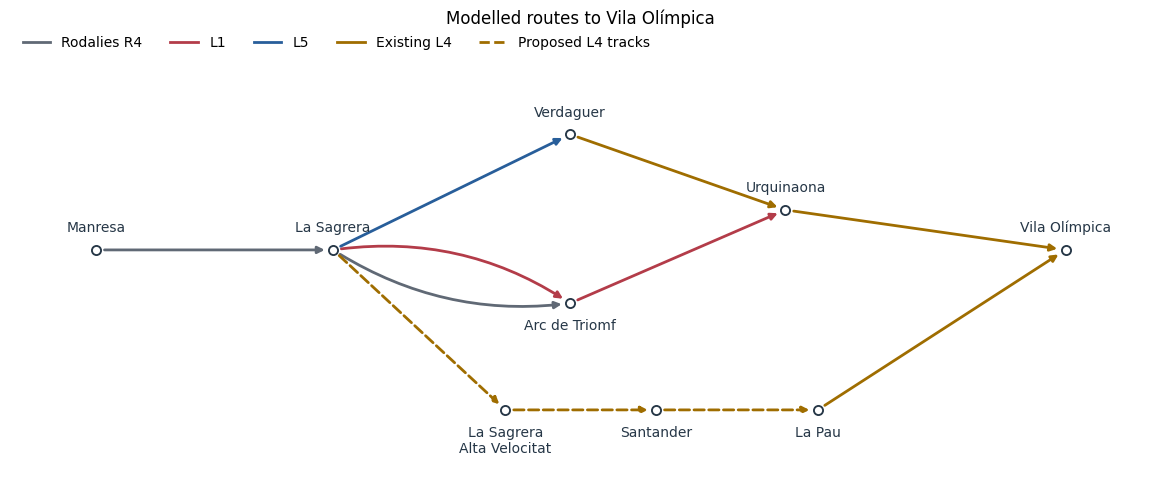

In [5]:
with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10}):
    network_fig, network_ax = plt.subplots(figsize=(11.5, 4.8), layout="constrained")
    positions = {
        "Manresa": (0.05, 0.52), "La Sagrera": (0.27, 0.52), "Arc de Triomf": (0.49, 0.40),
        "Verdaguer": (0.49, 0.78), "Urquinaona": (0.69, 0.61), "Vila Olímpica": (0.95, 0.52),
        "La Sagrera\nAlta Velocitat": (0.43, 0.16), "Santander": (0.57, 0.16), "La Pau": (0.72, 0.16),
    }
    rail, l1, l5, l4, extension = "#606975", "#B33C49", "#285E9A", "#9F6D00", "#9F6D00"
    diagram_edges = [
        ("Manresa", "La Sagrera", rail, "-", 0.0),
        ("La Sagrera", "Arc de Triomf", rail, "-", 0.18),
        ("La Sagrera", "Arc de Triomf", l1, "-", -0.19),
        ("Arc de Triomf", "Urquinaona", l1, "-", 0.0),
        ("La Sagrera", "Verdaguer", l5, "-", 0.0),
        ("Verdaguer", "Urquinaona", l4, "-", 0.0),
        ("Urquinaona", "Vila Olímpica", l4, "-", 0.0),
        ("La Sagrera", "La Sagrera\nAlta Velocitat", extension, "--", 0.0),
        ("La Sagrera\nAlta Velocitat", "Santander", extension, "--", 0.0),
        ("Santander", "La Pau", extension, "--", 0.0),
        ("La Pau", "Vila Olímpica", l4, "-", 0.0),
    ]
    for origin, destination, color, style, curvature in diagram_edges:
        network_ax.annotate("", xy=positions[destination], xytext=positions[origin],
                            arrowprops={"arrowstyle": "-|>", "color": color, "linewidth": 2,
                                        "linestyle": style, "shrinkA": 6, "shrinkB": 6,
                                        "connectionstyle": f"arc3,rad={curvature}"})
    for station, (x, y) in positions.items():
        network_ax.scatter(x, y, s=43, color="white", edgecolor="#263747", linewidth=1.35, zorder=3)
        below = station in {"La Sagrera\nAlta Velocitat", "Santander", "La Pau", "Arc de Triomf"}
        offset = -11 if below else 11
        network_ax.annotate(station, (x, y), xytext=(0, offset), textcoords="offset points",
                            ha="center", va="top" if below else "bottom", color="#263747")
    network_ax.legend(handles=[
        Line2D([0], [0], color=rail, label="Rodalies R4", lw=2),
        Line2D([0], [0], color=l1, label="L1", lw=2),
        Line2D([0], [0], color=l5, label="L5", lw=2),
        Line2D([0], [0], color=l4, label="Existing L4", lw=2),
        Line2D([0], [0], color=extension, ls="--", label="Proposed L4 tracks", lw=2),
    ], loc="upper left", ncol=5, frameon=False, bbox_to_anchor=(0, 1.02))
    network_ax.set(xlim=(-0.03, 1.03), ylim=(0, 1.01), title="Modelled routes to Vila Olímpica")
    network_ax.set_axis_off()
    plt.show()

The base cost is in-vehicle time plus 1.75 times scheduled waiting and 1.50 times time spent walking during transfers. Journey time is measured from boarding Rodalies at Manresa to arrival at the Vila Olímpica station.

For R4, the group estimates the ride from La Sagrera to La Pau as three intervals at $36/21$ minutes each. The existing La Pau–Vila Olímpica segment uses the GTFS ride time. A four-minute terminal headway gives a scheduled wait of two minutes under uniform arrivals.

In [6]:
def metro_total(segments, column):
    return float(metro.loc[segments, column].sum())


existing_segments = [
    ["Arc to Urquinaona", "Urquinaona to Vila Olímpica"],
    ["La Sagrera to Urquinaona", "Urquinaona to Vila Olímpica"],
    ["La Sagrera to Verdaguer", "Verdaguer to Vila Olímpica"],
]
l4_pau_to_vila = float(metro.loc["La Pau to Vila Olímpica", "ride_min"])
if EXISTING_L4_RIDE_OVERRIDE is not None:
    l4_pau_to_vila = EXISTING_L4_RIDE_OVERRIDE

ride_min = np.array([
    rail_min + metro_total(segments, "ride_min")
    for rail_min, segments in zip([R4_TO_ARC, R4_TO_SAGRERA, R4_TO_SAGRERA], existing_segments)
] + [R4_TO_SAGRERA + EXTENSION_RIDE_MIN + l4_pau_to_vila])
scheduled_wait_min = np.array([
    metro_total(segments, "scheduled_wait_min") for segments in existing_segments
] + [TERMINAL_HEADWAY_MIN / 2])
walking_min = np.array([
    WALK_R4_TO_L1_AT_ARC + WALK_L1_TO_L4_AT_URQUINAONA,
    WALK_R4_TO_L1_AT_SAGRERA + WALK_L1_TO_L4_AT_URQUINAONA,
    WALK_R4_TO_L5_AT_SAGRERA + WALK_L5_TO_L4_AT_VERDAGUER,
    WALK_R4_TO_L4_AT_SAGRERA,
])
base_cost = ride_min + WAIT_WEIGHT * scheduled_wait_min + WALK_WEIGHT * walking_min
base_journey_time = ride_min + scheduled_wait_min + walking_min

display(pd.DataFrame({
    "In vehicles (min)": ride_min, "Scheduled wait (min)": scheduled_wait_min,
    "Transfer walk (min)": walking_min, "Journey time (min)": base_journey_time,
    "Base cost (weighted min)": base_cost,
}, index=ROUTES).round(3))
handwritten_cost = R4_TO_SAGRERA + 12 + (36 / 21) * 3 + WAIT_WEIGHT * (4 / 2) + WALK_WEIGHT * 1
base_gain = base_cost[:3].min() - base_cost[3]
print(f"The group's rounded inputs give {handwritten_cost:.3f} weighted minutes for the new route.")
print(f"The GTFS ride from La Pau and the current settings give {base_cost[3]:.3f} weighted minutes.")
if base_gain > 0:
    print(f"Against the cheapest current base route, {base_gain / WAIT_WEIGHT:.2f} min of extra wait "
          "on the new route would offset its base advantage.")

,In vehicles (min),Scheduled wait (min),Transfer walk (min),Journey time (min),Base cost (weighted min)
R1,83.417,3.664,4.0,91.081,95.829
R2,84.561,3.719,4.0,92.280,97.069
R3,87.333,3.441,3.0,93.774,97.855
R4,88.476,2.000,1.0,91.476,93.476


The group's rounded inputs give 93.143 weighted minutes for the new route.
The GTFS ride from La Pau and the current settings give 93.476 weighted minutes.
Against the cheapest current base route, 1.34 min of extra wait on the new route would offset its base advantage.


# 4. Demand, available places and extra waiting

We draw $Q$, background passengers and spare places with lognormal multipliers. Each draw is reused for both networks. The existing metro counts are scaled by $0.10 \times 0.50 \times 0.05$. Background passengers are competing boarders. The assumed onboard shares represent riders already inside the train.

The new L4 boarding is at the assumed terminal. The reference case starts with zero onboard load and zero competing boarders there. Both inputs are editable.

If $q$ people arrive at a boarding point with $s$ free places per train, the first $s$ wait zero extra minutes, the next $s$ wait one headway $h$, and so on. We report the mean across the boarding batch and apply the same waiting weight to scheduled and additional waiting.

| Arrival assumption | Background boarders | Manresa–UPF passengers |
|---|---|---|
| Single boarding batch | One batch | One batch |
| Rodalies arrival wave | Spread across metro departures | One batch |
| Even arrivals | Spread across metro departures | Spread across metro departures |

The first row reproduces the earlier queue assumption. When a demand component is spread across departures, its total is multiplied by $h/120$ for the relevant service. This compares a boarding batch with places **per train**. The calculation is static and treats each representative batch in isolation.

In [7]:
headways = np.array([
    metro.loc["Arc to Urquinaona", "headway_min"],
    metro.loc["La Sagrera to Verdaguer", "headway_min"],
    metro.loc["Urquinaona to Vila Olímpica", "headway_min"],
    TERMINAL_HEADWAY_MIN,
], dtype=float)
background_period = np.r_[
    fmb_month.weekday_passengers.to_numpy() * WINDOW_SHARE * DIRECTION_SHARE * BACKGROUND_SCALE,
    TERMINAL_BACKGROUND_IN_WINDOW,
]
nominal_spare = METRO_CAPACITY * (1 - METRO_ONBOARD_SHARE)
if (nominal_spare <= 0).any() or (headways <= 0).any() or (background_period < 0).any() or Q_BASE <= 0:
    raise ValueError("Use positive demand, spare capacity and headways, and nonnegative background demand.")

display(pd.DataFrame({
    "Headway (min)": headways, "Background per window": background_period,
    "Assumed onboard share": METRO_ONBOARD_SHARE, "Nominal spare places per train": nominal_spare,
}, index=SERVICES).round(3))

ARRIVAL_PATTERNS = {
    "Single boarding batch": (False, False),
    "Rodalies arrival wave": (True, False),
    "Even arrivals": (True, True),
}


def draw_scenarios(n=N_SCENARIOS, seed=SEED):
    if n <= 0:
        raise ValueError("Generate at least one scenario.")
    rng = np.random.default_rng(seed)
    terminal_rng = np.random.default_rng(np.random.SeedSequence([seed, 1]))
    scenarios = []
    for _ in range(n):
        demand = Q_BASE * rng.lognormal(0, DEMAND_LOG_SD)
        background = background_period * np.r_[
            rng.lognormal(0, BACKGROUND_LOG_SD, size=3),
            terminal_rng.lognormal(0, BACKGROUND_LOG_SD),
        ]
        capacity_draw = nominal_spare * np.r_[
            rng.lognormal(0, SPARE_CAPACITY_LOG_SD, size=3),
            terminal_rng.lognormal(0, SPARE_CAPACITY_LOG_SD),
        ]
        scenarios.append({
            "demand": demand, "background": background,
            "spare_places": np.minimum(capacity_draw, METRO_CAPACITY),
        })
    return scenarios


def extra_wait(queue, spare_places, headway):
    """Mean extra minutes for a batch facing successive trains of equal spare capacity."""
    if queue < 0 or spare_places <= 0 or headway <= 0:
        raise ValueError("Use a nonnegative queue and positive spare places and headway.")
    if queue <= spare_places:
        return 0.0
    full_trains = int(queue // spare_places)
    remainder = queue - full_trains * spare_places
    missed_trains = spare_places * full_trains * (full_trains - 1) / 2 + remainder * full_trains
    return headway * missed_trains / queue


def integrated_extra_wait(queue, spare_places, headway):
    """Area under extra_wait from zero to queue."""
    area = 0.0
    for full_trains in range(1, int(queue // spare_places) + 1):
        low = full_trains * spare_places
        high = min(queue, (full_trains + 1) * spare_places)
        if high > low:
            area += headway * (
                full_trains * (high - low)
                - spare_places * full_trains * (full_trains + 1) / 2 * np.log(high / low)
            )
    return area

,Headway (min),Background per window,Assumed onboard share,Nominal spare places per train
L1 toward Hospital de Bellvitge,3.029,47.920,0.80,20.0
L5 toward Cornellà Centre,2.505,55.056,0.75,25.0
L4 via Urquinaona,4.237,33.367,0.80,20.0
L4 from La Sagrera via La Pau,4.000,0.000,0.00,100.0


# 5. Route-choice equilibrium

At a Wardrop equilibrium, every used route has the lowest available perceived cost. Without capacity delays, the model assigns the group to the cheapest base route. With congestion, the solver uses the integral of each service’s waiting cost to find an equilibrium and checks the largest remaining gain from switching. Route flows represent continuous passenger volumes.

As a check, the textbook Braess network raises equilibrium travel time from 65 to 80 minutes. Its shortcut combines the two congestible links from the existing routes. [Textbook example](https://www.cs.cornell.edu/home/kleinber/networks-book/networks-book-ch08.pdf)

In [8]:
def wardrop_assignment(demand, matrix, base, resource_cost, integrated_resource_cost):
    """Return equilibrium route shares and the largest gain from switching."""
    n_routes = len(base)

    def route_cost(shares):
        return base + matrix.T @ resource_cost(matrix @ (demand * shares))

    def potential(shares):
        use = matrix @ (demand * shares)
        return (base - base.min()) @ shares + integrated_resource_cost(use).sum() / demand

    constraints = {"type": "eq", "fun": lambda shares: shares.sum() - 1.0,
                   "jac": lambda shares: np.ones(n_routes)}
    equal_shares = np.full(n_routes, 1.0 / n_routes)
    cheapest_only = np.eye(n_routes)[np.argmin(route_cost(equal_shares))]
    for initial in (equal_shares, cheapest_only):
        solution = minimize(
            potential, initial, jac=lambda shares: route_cost(shares) - base.min(),
            bounds=[(0.0, 1.0)] * n_routes, constraints=constraints, method="SLSQP",
            options={"ftol": 1e-13, "maxiter": 350},
        )
        shares = np.clip(solution.x, 0.0, 1.0)
        shares[shares < 1e-8] = 0.0
        if shares.sum() == 0:
            continue
        shares /= shares.sum()
        costs = route_cost(shares)
        gap = float(costs[shares > 0].max() - costs.min())
        if gap <= WARDROP_TOL:
            return shares, gap
    raise RuntimeError(f"Equilibrium check failed. Solver message: {solution.message}")


def solve_network(scenario, *, extended, congestion, pattern="Single boarding batch"):
    count = len(ROUTES) if extended else len(ROUTES) - 1
    matrix = incidence[:count, :count]
    base = base_cost[:count]
    demand = scenario["demand"]
    spare = scenario["spare_places"][:count]
    headway = headways[:count]
    spread_background, spread_group = ARRIVAL_PATTERNS[pattern]
    per_departure = headway / WINDOW_MIN
    background = scenario["background"][:count] * (per_departure if spread_background else 1.0)
    group_factor = per_departure if spread_group else np.ones(count)

    def queues(service_flow):
        return background + group_factor * service_flow

    def service_waits(service_flow):
        return np.array([extra_wait(q, s, h) for q, s, h in zip(queues(service_flow), spare, headway)])

    if congestion:
        integral_base = np.array([
            integrated_extra_wait(q, s, h) for q, s, h in zip(background, spare, headway)
        ])

        def resource_cost(service_flow):
            return WAIT_WEIGHT * service_waits(service_flow)

        def integrated_resource_cost(service_flow):
            area = np.array([
                integrated_extra_wait(q, s, h) for q, s, h in zip(queues(service_flow), spare, headway)
            ])
            return WAIT_WEIGHT * (area - integral_base) / group_factor

        shares, gap = wardrop_assignment(demand, matrix, base, resource_cost, integrated_resource_cost)
        waits_by_service = service_waits(matrix @ (demand * shares))
    else:
        shares = np.eye(count)[np.argmin(base)]
        gap, waits_by_service = 0.0, np.zeros(count)

    flows = demand * shares
    waits_by_route = matrix.T @ waits_by_service
    costs = base + WAIT_WEIGHT * waits_by_route
    journey_times = base_journey_time[:count] + waits_by_route
    return {
        "flows": flows, "route_costs": costs, "mean_cost": float(shares @ costs),
        "mean_journey_min": float(shares @ journey_times), "mean_extra_wait_min": float(shares @ waits_by_route),
        "service_wait_min": waits_by_service, "route_wait_min": waits_by_route,
        "service_queue": queues(matrix @ flows), "gap": gap,
    }

In [9]:
assert np.isclose(extra_wait(20, 100, 4), 0)
assert np.isclose(extra_wait(120, 100, 4), 20 * 4 / 120)
assert np.isclose(extra_wait(250, 100, 4), (100 * 4 + 50 * 8) / 250)

classic_matrix = np.array([[1, 0, 1], [0, 1, 1]], dtype=float)
classic_base = np.array([45.0, 45.0, 0.0])
classic_equilibrium_costs = []
for n_routes in (2, 3):
    matrix = classic_matrix[:, :n_routes]
    base = classic_base[:n_routes]
    classic_shares, _ = wardrop_assignment(
        4000, matrix, base, lambda use: use / 100, lambda use: use ** 2 / 200,
    )
    equilibrium_cost = classic_shares @ (base + matrix.T @ (matrix @ (4000 * classic_shares) / 100))
    classic_equilibrium_costs.append(equilibrium_cost)
np.testing.assert_allclose(classic_equilibrium_costs, [65, 80], atol=WARDROP_TOL)
print("Queue checks passed. Classic Braess benchmark: 65 → 80 minutes.")

Queue checks passed. Classic Braess benchmark: 65 → 80 minutes.


# 6. Result 1 — One scenario

The same passenger draw is solved four ways. In the congested cases, the route table gives the equilibrium allocation and cost. The service table gives the queue and extra wait separately for each boarding resource.

In [10]:
scenarios = draw_scenarios()
example = scenarios[0]
reference_pattern = "Single boarding batch"
current_base = solve_network(example, extended=False, congestion=False)
extended_base = solve_network(example, extended=True, congestion=False)
current_example = solve_network(example, extended=False, congestion=True, pattern=reference_pattern)
extended_example = solve_network(example, extended=True, congestion=True, pattern=reference_pattern)

print(f"Illustrative scenario: Q = {example['demand']:.3f} passengers.")
example_cases = {
    "Current · no congestion": current_base, "Current · with congestion": current_example,
    "Extended · no congestion": extended_base, "Extended · with congestion": extended_example,
}
display(pd.DataFrame.from_dict({
    name: {
        "Mean cost (weighted min)": outcome["mean_cost"],
        "Mean journey time (min)": outcome["mean_journey_min"],
        "Mean extra wait (min)": outcome["mean_extra_wait_min"],
    } for name, outcome in example_cases.items()
}, orient="index").round(3))
display(pd.DataFrame({
    "Base cost": base_cost,
    "Current flow": np.r_[current_example["flows"], np.nan],
    "Current congested cost": np.r_[current_example["route_costs"], np.nan],
    "Extended flow": extended_example["flows"],
    "Extended congested cost": extended_example["route_costs"],
}, index=ROUTES).round(3))
display(pd.DataFrame({
    "Spare places per train": example["spare_places"],
    "Current queue": np.r_[current_example["service_queue"], np.nan],
    "Current extra wait (min)": np.r_[current_example["service_wait_min"], np.nan],
    "Extended queue": extended_example["service_queue"],
    "Extended extra wait (min)": extended_example["service_wait_min"],
}, index=SERVICES).round(3))

Illustrative scenario: Q = 28.523 passengers.


,Mean cost (weighted min),Mean journey time (min),Mean extra wait (min)
Current · no congestion,95.829,91.081,0.000
Current · with congestion,108.045,98.768,6.447
Extended · no congestion,93.476,91.476,0.000
Extended · with congestion,93.476,91.476,0.000


,Base cost,Current flow,Current congested cost,Extended flow,Extended congested cost
R1,95.829,15.390,108.045,0.000,101.398
R2,97.069,0.000,109.285,0.000,102.638
R3,97.855,13.133,108.045,0.000,102.620
R4,93.476,NaN,NaN,28.523,93.476


,Spare places per train,Current queue,Current extra wait (min),Extended queue,Extended extra wait (min)
L1 toward Hospital de Bellvitge,18.958,53.996,2.868,38.605,1.596
L5 toward Cornellà Centre,29.399,66.936,1.710,53.803,1.136
L4 via Urquinaona,21.675,63.171,4.113,34.648,1.587
L4 from La Sagrera via La Pau,92.017,NaN,NaN,28.523,0.000


# 7. Result 2 — Paired Monte Carlo comparison

Each row compares the **same draw** before and after the extension. The current congestion premium is the current congested cost minus the current base cost. The extension effect is the difference between the two congested equilibrium costs.

$$
\Delta C_{\mathrm{extension},i}=C^{*}_{\mathrm{extended},i}-C^{*}_{\mathrm{current},i}.
$$

Values beyond the tolerance set by CHANGE_TOL, initially 0.01 weighted minutes, count as a saving if negative or an increase if positive. The resulting shares describe the simulated scenarios.

In [11]:
def run_monte_carlo(scenarios, pattern):
    rows = []
    for number, scenario in enumerate(scenarios, start=1):
        before = solve_network(scenario, extended=False, congestion=True, pattern=pattern)
        after = solve_network(scenario, extended=True, congestion=True, pattern=pattern)
        row = {
            "scenario": number, "demand": scenario["demand"],
            "current_base_cost": current_base["mean_cost"],
            "extended_base_cost": extended_base["mean_cost"],
            "current_cost": before["mean_cost"], "extended_cost": after["mean_cost"],
            "current_congestion_premium": before["mean_cost"] - current_base["mean_cost"],
            "extended_congestion_premium": after["mean_cost"] - extended_base["mean_cost"],
            "extension_effect": after["mean_cost"] - before["mean_cost"],
            "current_extra_wait": before["mean_extra_wait_min"],
            "extended_extra_wait": after["mean_extra_wait_min"],
            "max_equilibrium_gap": max(before["gap"], after["gap"]),
        }
        for route, flow in zip(ROUTES, before["flows"]):
            row[f"current_flow_{route}"] = flow
        for route, flow in zip(ROUTES, after["flows"]):
            row[f"extended_flow_{route}"] = flow
        rows.append(row)
    return pd.DataFrame(rows)


simulations = {pattern: run_monte_carlo(scenarios, pattern) for pattern in ARRIVAL_PATTERNS}
results = simulations[reference_pattern]
summary_rows = []
for pattern, table in simulations.items():
    delta = table["extension_effect"]
    summary_rows.append({
        "Arrival assumption": pattern, "Scenarios": len(table),
        "Current cost": table.current_cost.mean(), "Extended cost": table.extended_cost.mean(),
        "Current congestion premium": table.current_congestion_premium.mean(),
        "Median current congestion premium": table.current_congestion_premium.median(),
        "Mean extension effect": delta.mean(), "Median extension effect": delta.median(),
        "5th percentile": delta.quantile(0.05), "95th percentile": delta.quantile(0.95),
        "Saving (%)": 100 * (delta < -CHANGE_TOL).mean(),
        "Within tolerance (%)": 100 * (delta.abs() <= CHANGE_TOL).mean(),
        "Increase (%)": 100 * (delta > CHANGE_TOL).mean(),
    })

    before_flows = table[[f"current_flow_{route}" for route in ROUTES[:3]]].sum(axis=1)
    after_flows = table[[f"extended_flow_{route}" for route in ROUTES]].sum(axis=1)
    np.testing.assert_allclose(before_flows, table.demand)
    np.testing.assert_allclose(after_flows, table.demand)
    assert (table.max_equilibrium_gap <= WARDROP_TOL).all()

summary = pd.DataFrame(summary_rows).set_index("Arrival assumption")
display(results[["scenario", "demand", "current_cost", "extended_cost",
                 "current_congestion_premium", "extension_effect", "extended_flow_R4"]].head().round(3))
display(summary[["Scenarios", "Current cost", "Extended cost", "Current congestion premium",
                 "Median current congestion premium", "Mean extension effect"]].round(3))
display(summary[["Median extension effect", "5th percentile", "95th percentile",
                 "Saving (%)", "Within tolerance (%)", "Increase (%)"]].round(3))

,scenario,demand,current_cost,extended_cost,current_congestion_premium,extension_effect,extended_flow_R4
0,1,28.523,108.045,93.476,12.216,-14.569,28.523
1,2,23.269,108.402,93.476,12.573,-14.926,23.269
2,3,24.595,108.849,93.476,13.020,-15.373,24.595
3,4,24.027,110.563,93.476,14.734,-17.087,24.027
4,5,26.486,109.664,93.476,13.835,-16.188,26.486


,Scenarios,Current cost,Extended cost,Current congestion premium,Median current congestion premium,Mean extension effect
Arrival assumption,,,,,,
Single boarding batch,500,109.083,93.476,13.254,13.100,-15.607
Rodalies arrival wave,500,98.738,93.476,2.909,3.053,-5.262
Even arrivals,500,95.829,93.476,0.000,0.000,-2.353


,Median extension effect,5th percentile,95th percentile,Saving (%),Within tolerance (%),Increase (%)
Arrival assumption,,,,,,
Single boarding batch,-15.452,-18.324,-13.435,100.0,0.0,0.0
Rodalies arrival wave,-5.406,-7.352,-2.683,100.0,0.0,0.0
Even arrivals,-2.353,-2.353,-2.353,100.0,0.0,0.0


# 8. Figures and interpretation

Panels A and B show the congestion premium in the current network under the single-batch assumption. The line in B is a descriptive fit across draws, where background demand and spare places also vary. Panel C compares the paired extension effect across the three arrival assumptions. Each line shows the mean and the central 90% of simulated effects.

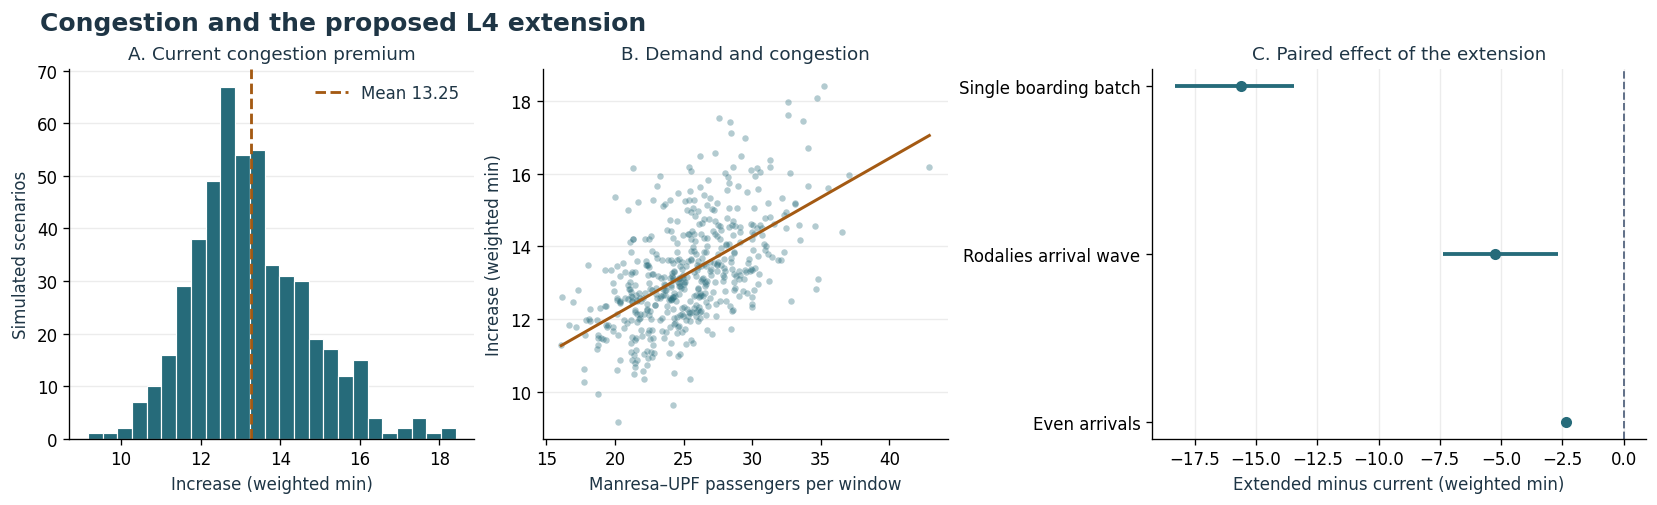

In [12]:
ink, teal, amber, slate = "#1E3545", "#266B7A", "#A45A13", "#63728A"
with plt.rc_context({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.labelcolor": ink, "text.color": ink,
    "axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.24,
    "axes.titlesize": 11, "figure.dpi": 120,
}):
    fig, axes = plt.subplots(1, 3, figsize=(13.7, 4.1), layout="constrained",
                             gridspec_kw={"width_ratios": [1, 1, 1.22]})
    fig.suptitle("Congestion and the proposed L4 extension", x=0.02, ha="left",
                 fontsize=15, fontweight="bold")
    current_premium = results.current_congestion_premium.to_numpy()
    demand_draws = results.demand.to_numpy()
    axes[0].hist(current_premium, bins=25, color=teal, edgecolor="white", linewidth=0.7)
    axes[0].axvline(current_premium.mean(), color=amber, linestyle="--", lw=1.7,
                    label=f"Mean {current_premium.mean():.2f}")
    axes[0].set(title="A. Current congestion premium", xlabel="Increase (weighted min)",
                ylabel="Simulated scenarios")
    axes[0].legend(frameon=False)
    axes[0].grid(axis="y")
    axes[0].set_axisbelow(True)

    axes[1].scatter(demand_draws, current_premium, s=15, alpha=0.35, color=teal, linewidths=0)
    if np.ptp(demand_draws) > 0:
        slope, intercept = np.polyfit(demand_draws, current_premium, 1)
        fit_x = np.linspace(demand_draws.min(), demand_draws.max(), 100)
        axes[1].plot(fit_x, intercept + slope * fit_x, color=amber, lw=1.8)
    axes[1].set(title="B. Demand and congestion", xlabel="Manresa–UPF passengers per window",
                ylabel="Increase (weighted min)")
    axes[1].grid(axis="y")
    axes[1].set_axisbelow(True)

    mean = summary["Mean extension effect"].to_numpy()
    low = summary["5th percentile"].to_numpy()
    high = summary["95th percentile"].to_numpy()
    y_positions = np.arange(len(summary))
    axes[2].hlines(y_positions, low, high, color=teal, lw=2.3)
    axes[2].scatter(mean, y_positions, s=32, color=teal, zorder=3)
    axes[2].axvline(0, color=slate, linestyle="--", lw=1.2)
    axes[2].set(title="C. Paired effect of the extension", xlabel="Extended minus current (weighted min)",
                yticks=y_positions, yticklabels=list(summary.index))
    axes[2].invert_yaxis()
    axes[2].grid(axis="x")
    axes[2].set_axisbelow(True)
    plt.show()

In [13]:
reference = summary.loc[reference_pattern]
print(f"Current congestion premium under the single-batch assumption: "
      f"{reference['Current congestion premium']:.2f} weighted minutes on average.")
for pattern, row in summary.iterrows():
    print(f"{pattern}: mean change from the extension = {row['Mean extension effect']:+.2f} "
          f"weighted minutes; {row['Increase (%)']:.1f}% of draws show an increase.")

Current congestion premium under the single-batch assumption: 13.25 weighted minutes on average.
Single boarding batch: mean change from the extension = -15.61 weighted minutes; 0.0% of draws show an increase.
Rodalies arrival wave: mean change from the extension = -5.26 weighted minutes; 0.0% of draws show an increase.
Even arrivals: mean change from the extension = -2.35 weighted minutes; 0.0% of draws show an increase.


In the single-batch case the model pools the two-hour totals into a single queue. Spreading background demand or both arrivals over departures changes the crowding at the boarding point and the resulting gain from the extension.

The new route has its own boarding resource. Switching to it reduces or leaves constant the demand on the existing resources, whose waiting costs increase weakly with demand. In this network of parallel choices, the equilibrium cost can therefore fall or stay the same. Modelling a future shared transfer bottleneck or a change in service frequency would require its own evidence and assumptions.

# 9. Sources and scope

- TMB schedule data, supplied GTFS extract for 16 November 2026, 08:00–10:00. [TMB developer portal](https://www.tmb.cat/es/tmb-app-y-otras-aplicaciones/herramientas-para-desarrolladores)
- FMB 2025 weekday passenger workbook, sheet `Feiners`, October by default. Counts are daily station totals. Boarding direction, onboard load and the Manresa–UPF origin–destination flow are scenario inputs. [TMB demand data](https://transparencia.tmb.cat/en/public-services/letters-and-service-catalog/provided-services-catalog/basic-and-demand-information)
- The group’s route notes provide provisional Rodalies ride times, walking times, wait and walk weights, and the new-segment travel-time estimate. The Fabra i Puig and Catalunya routes in those notes are candidate alternatives for a wider route set.
- Generalitat de Catalunya, project release of 25 November 2024. The extension connects La Pau to La Sagrera, with Santander and Sagrera Alta Velocitat between them. [Project release](https://govern.cat/govern/docs/2024/11/25/13/32/520cdf47-5329-4033-a5ee-6a008800ebce.pdf)
- Easley and Kleinberg (2010), *Networks, Crowds, and Markets*, Chapter 8. [Chapter](https://www.cs.cornell.edu/home/kleinber/networks-book/networks-book-ch08.pdf)
- Braess, Nagurney and Wakolbinger (2005), “On a Paradox of Traffic Planning,” *Transportation Science*, 39(4), 446–450. [Article](https://doi.org/10.1287/trsc.1050.0127)

In [14]:
display(provenance)

,file,sha256
0,routes.txt,3d2f58f3860bd513f37e7d8ab8bf7da6c590850bf97725...
1,trips.txt,65d236fd5607d74c8f026e392c416d4125fe60440af70b...
2,stop_times.txt,a729527f23788fdd1463c6f27bd70d8b96c5420f6c9176...
3,calendar.txt,4349e26a89cfd35acadeba9a410b6f305589e7c41dd13e...
4,calendar_dates.txt,5b21bb677c425324c07bb4cdae5edfc80b5b47fec874db...
5,Resum dades mensuals i diàries de viatgers FM...,e7563e545f8916cc66dcd50f3ffc16ad45b52f221c7dbf...


## Pt. II: Conditions under which the paradox could appear